# Recherche d’amélioration sur les grandes instances CVRPTW

**Bilan des pipelines de 120 s : 9.036 % pour deux phases ILS ; 4.253 % pour ILS puis HGS externe.** La cible moyenne de 6 % est atteinte par cette seconde combinaison sur les douze cas étudiés et deux graines. Cette combinaison comprend une bibliothèque externe, explicitement attribuée ; elle ne remplace pas automatiquement la métaheuristique évaluée.


## Conclusion mesurée et statut

Sur les douze instances historiques à 1 000 clients, avec deux nouvelles graines et 60 secondes de recherche, notre ILS obtient **9.598 %** de gap moyen. Le comparateur **construction propre puis HGS externe PyVRP 0.12.2** obtient **6.624 %**, avec 24/24 solutions finales réalisables. La cible moyenne de 6 % est encore manquée par ce comparateur. Le pire essai externe reste à **41.238 %** : une moyenne sous 6 % ne signifie pas que tous les essais sont sous 6 %.

Le moteur par défaut et le livrable évalué restent notre ILS. PyVRP est une bibliothèque externe, et sa recherche génétique n’est pas notre implémentation. L’utilisateur a confirmé que le moteur externe est autorisé ; il reste explicitement attribué à PyVRP. La construction propre utilisée ici est une initialisation par insertion ; aucune phase d’optimisation ILS ne précède le HGS dans cette campagne.

## Problème, unités et calcul du gap

Le problème conserve la capacité, les fenêtres strictes sur le début de service, l’attente autorisée, la couverture exactement une fois, le retour au dépôt et la borne de flotte. La distance seule est minimisée selon la convention DIMACS : chaque arc vaut floor(10 × distance euclidienne) en interne. Les temps de trajet et les fenêtres utilisent la même échelle. Le moteur ne lit aucune BKS.

Après résolution, le vérificateur indépendant recalcule la distance D et toutes les contraintes sur les données originales. Pour une référence compatible B : **gap = 100 × (D − B) / B**. Une BKS est la meilleure solution connue, pas une preuve d’optimalité. Notre comparaison utilise les fichiers .sol du jeu figé et vérifie aussi ces solutions. La flotte est ici une contrainte maximale, pas le premier objectif : il ne faut pas mélanger cette comparaison avec la référence SINTEF hiérarchique.

La moyenne est la moyenne arithmétique des 24 gaps de chaque méthode, soit deux essais pour chacune des douze instances. Toutes les instances ont donc le même poids. Aucun seuil de gap ne sert à sélectionner les résultats. Les distances et les flottes de chaque exécution figurent dans le CSV complet.

## Hypothèses réellement implémentées dans notre code

1. **Coût guidé** (`algo/guided.py`) : des pénalités d’arcs fréquemment présents modifient seulement le coût de recherche. Les temps de trajet et contraintes restent inchangés. Seule la distance originale classe l’archive finale.
2. **Exploration pénalisée** (`algo/penalty_hybrid.py`) : les mouvements atomiques conservent tous les clients et la borne de flotte. Les états de travail peuvent dépasser la capacité ou les horaires. L’objectif de travail est F = D + wQ × excès de charge + wT × décalage temporel. Une arrivée tardive accumule un décalage puis ramène l’horloge à la borne de fin ; un décalage nul correspond à l’absence de violation temporelle. L’archive finale accepte exclusivement les états réalisables sur les contraintes originales.
3. **Descente pénalisée** (`algo/penalty_descent.py`, `algo/penalty_ils.py`) : relocate, swap, 2-opt et 2-opt* sont évalués sur ce coût de travail. Les poids sont adaptés à la fréquence des états réalisables. Les raccourcis fondés sur la seule distance sont utilisés seulement lorsque les routes concernées sont déjà réalisables.
4. **ILS pénalisée approfondie** (`algo/intensive_ils.py`) : quatre à douze perturbations acceptées au maximum, puis une descente jusqu’à un optimum local, en continuant la descente lorsqu’un bloc de 300 mouvements est épuisé. Cette variante corrige les perturbations trop longues de la première tentative.

Ces variantes sont des expériences distinctes. Les tests confirment la validité de leur archive et l’intégrité des données ; ils ne démontrent pas leur performance. Les gains observés sont insuffisamment réguliers pour remplacer le moteur courant.

## Développement : gains et régressions

Trois instances difficiles séparées de la confirmation : C2_10_8, R2_10_8 et RC2_10_8. Les deux premières campagnes utilisent la graine 2002 ; la troisième utilise 2003. Chaque campagne réexécute sa référence. Même une graine identique peut produire des résultats différents sous un arrêt au temps, puisque le nombre d’itérations dépend de l’exécution. Il faut comparer les méthodes dans leur campagne, sans choisir la référence la plus favorable a posteriori.

| campaign | variant | planned | executed | valid | failures | mean_gap | std_gap | best_gap | worst_gap | below_6 | mean_total_s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| development | ILS propre | 3 | 3 | 3 | 0 | 9,692 | 7,237 | 2,905 | 17,307 | 1 | 64,266 |
| development | HGS externe, départ libre | 3 | 3 | 0 | 3 | — | — | — | — | 0 | — |
| development | Construction propre + HGS externe | 3 | 3 | 3 | 0 | 3,745 | 2,786 | 0,542 | 5,611 | 3 | 64,505 |
| development | ILS et coût guidé | 3 | 3 | 3 | 0 | 10,011 | 5,547 | 4,507 | 15,600 | 1 | 64,613 |
| development | Exploration pénalisée | 3 | 3 | 3 | 0 | 10,458 | 8,336 | 4,368 | 19,958 | 1 | 64,354 |
| development | Pénalités, température forte | 3 | 3 | 3 | 0 | 11,945 | 5,840 | 7,499 | 18,559 | 0 | 64,402 |
| development_descent | ILS propre | 3 | 3 | 3 | 0 | 12,145 | 7,867 | 7,218 | 21,218 | 0 | 64,474 |
| development_descent | HGS externe, départ libre | 3 | 3 | 3 | 0 | 4,750 | 1,964 | 2,486 | 5,987 | 3 | 60,302 |
| development_descent | ILS pénalisée | 3 | 3 | 3 | 0 | 11,737 | 4,359 | 7,970 | 16,511 | 0 | 64,297 |
| development_intensive | ILS propre | 3 | 3 | 3 | 0 | 13,112 | 7,477 | 7,871 | 21,675 | 0 | 64,796 |
| development_intensive | ILS pénalisée approfondie | 3 | 3 | 3 | 0 | 13,199 | 3,680 | 10,076 | 17,256 | 0 | 64,522 |

Les trois échecs du premier départ libre externe sont des erreurs techniques de l’adaptateur lors de la récupération de sa version, après le calcul. Ils sont conservés avec leur traceback et ne sont ni des instances infaisables ni des résultats à gap nul. L’erreur a été corrigée puis trois nouveaux essais ont été exécutés sous un nouveau protocole. Les anciens essais n’ont pas été écrasés. Leur durée totale n’avait pas été enregistrée ; elle n’est pas remplacée par zéro.

## Confirmation sur les douze grandes instances

Les familles C1, C2, R1, R2, RC1 et RC2 sont représentées par les suffixes 3 et 4. Graines 2101 et 2102 ; 24 résolutions par méthode ; plafond de recherche de 60 s ; six processus, un cœur physique par processus et un seul thread. La même construction déterministe est utilisée pour chaque paire instance–graine. La préparation externe et la construction sont mesurées, la compilation est préchauffée hors budget. Les temps ne doivent pas être assimilés à ceux d’un ordinateur différent.

| variant | planned | executed | valid | failures | mean_gap | std_gap | best_gap | worst_gap | below_6 | mean_total_s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS propre | 24 | 24 | 24 | 0 | 9,598 | 5,168 | 2,908 | 18,532 | 9 | 64,380 |
| Construction propre + HGS externe | 24 | 24 | 24 | 0 | 6,624 | 7,768 | 1,330 | 41,238 | 18 | 64,690 |

L’écart-type global mélange les différences entre instances et les variations entre graines. Il ne mesure donc pas uniquement l’aléa de l’algorithme. Les écarts-types par instance, fondés ici sur seulement deux valeurs, restent très incertains.

| instance | ILS propre : gap moyen (%) | HGS externe : gap moyen (%) |
| --- | --- | --- |
| C1_10_3 | 3,378 | 3,640 |
| C1_10_4 | 5,255 | 3,237 |
| C2_10_3 | 10,884 | 1,884 |
| C2_10_4 | 13,292 | 5,218 |
| R1_10_3 | 6,355 | 27,221 |
| R1_10_4 | 5,866 | 4,340 |
| R2_10_3 | 10,926 | 7,948 |
| R2_10_4 | 17,703 | 7,518 |
| RC1_10_3 | 4,908 | 4,311 |
| RC1_10_4 | 4,318 | 3,436 |
| RC2_10_3 | 15,331 | 5,112 |
| RC2_10_4 | 16,964 | 5,617 |

Le gain moyen apparié est **2.975 points**. L’intervalle exploratoire à 95 % par rééchantillonnage des douze instances est [-2.356 ; 7.018] points. Deux graines par instance restent limitées. Ces douze cas étaient déjà étudiés dans les campagnes précédentes : c’est une confirmation sur le lot difficile, pas une évaluation indépendante sur toutes les 60 instances à 1 000 clients.

![Comparaison par instance](../livraison/ils_v7_figures/comparison.png)

![Dispersion des 48 essais](../livraison/ils_v7_figures/distribution.png)

![Temps réels et qualité](../livraison/ils_v7_figures/time_gap.png)

## Ce que la référence externe nous apprend

L’article de Kool et ses coauteurs présente une recherche génétique hybride pour le VRPTW avec capacité et objectif de distance DIMACS. Elle combine population diversifiée, croisement de tournées, amélioration locale et pénalités de capacité/temps. Notre interprétation est que la diversification structurelle et l’efficacité de la recherche locale expliquent une partie de l’écart ; nos essais ne permettent pas d’isoler causalement chaque mécanisme.

Notre diagnostic pour la suite : une population diversifiée ou une recombinaison de tournées peut aider à changer la répartition des clients, mais ajouter des pénalités à une trajectoire unique n’a pas suffi dans nos essais. Une implémentation propre de ces mécanismes demanderait une nouvelle phase de développement et de validation. Les concaténations de segments temporels restent une piste d’accélération ; elles ne sont pas présentées comme déjà implémentées ici.

## Reproduire et lire les résultats

`results/optimization_v7/confirmation_external/protocol.json` fige les instances, graines, budgets, ordre des tâches et empreintes du code. Le sous-dossier `source/` conserve les sources réellement exécutées. `runs/` contient chaque solution complète, ses mesures et sa graine. `flat.csv`, `instances.csv`, `summary.csv` et `analysis.json` sont recalculables par `python scripts/analyze_v7.py confirmation_external`.

Le notebook `notebooks/Recherche_1000_clients_V7.ipynb` est exécuté sur ces données, sans relancer secrètement les recherches. `livraison/RESULTATS_ILS_V7.csv` rassemble les 129 exécutions des cinq campagnes, dont trois échecs techniques. Le pilote antérieur de trois départs libres à 20 s reste un diagnostic séparé dans `external_pilot/` : il n’entre dans aucune moyenne de confirmation.

Pour une référence manuelle explicite : `python scripts/run_external_reference.py R2_10_3 --seconds 60 --seed 2101 --our-construction`. Installer auparavant les dépendances facultatives avec `python -m pip install -r requirements-reference-v7.txt`. Cette commande ne change pas l’ILS par défaut.

## Sources et attribution

- Kool et al., *Hybrid Genetic Search for the Vehicle Routing Problem with Time Windows: a High-Performance Implementation* : https://wouterkool.github.io/pdf/paper-kool-hgs-vrptw.pdf
- Source de PyVRP **0.12.2** réellement utilisée, fondée sur `GeneticAlgorithm` : https://github.com/PyVRP/PyVRP/blob/v0.12.2/pyvrp/solve.py
- Licence MIT et auteurs de la bibliothèque : https://github.com/PyVRP/PyVRP/blob/v0.12.2/LICENSE.md
- Voudouris et Tsang, principe général du coût guidé, étudié dans cet article pour le voyageur de commerce : https://www.sciencedirect.com/science/article/pii/S037722179800099X . Il ne constitue pas une preuve de gain pour notre CVRPTW.

La version externe est épinglée : les versions récentes de PyVRP ont une architecture différente et ne doivent pas être confondues avec ce HGS 0.12.2.


## Complément décisif : ILS puis moteur génétique externe

L’essai naïf à 60 s a révélé une régression majeure : sur R1_10_3, graine 2101, le moteur externe a conservé la construction initiale à 41,238 %. Cette valeur n’est pas supprimée. Le démarrage réalisable ne garantit pas une bonne initialisation, et une minute n’a pas suffi à ce moteur pour la corriger sur ce cas.

Nous réutilisons donc les **24 sorties ILS réellement calculées pendant 60 s** dans la campagne précédente. À partir de chaque même sortie, deux nouvelles branches sont exécutées : ILS pendant 60 s, ou HGS externe pendant 60 s. La graine de seconde phase est la graine initiale + 10 000 pour les deux branches. Les deux pipelines sont ainsi facturés à 120 s de recherche, avec la même construction et leurs préparations effectives. Les 24 préfixes sont réutilisés, pas recalculés : la nouvelle campagne exécute **48 secondes phases**. Les branches partagent leur première phase ; elles sont appariées et ne doivent pas être traitées comme deux expériences indépendantes.

| variant | planned | executed | valid | failures | mean_gap | std_gap | best_gap | worst_gap | below_6 | mean_total_s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS propre 60 s + ILS propre 60 s | 24 | 24 | 24 | 0 | 9,036 | 4,975 | 2,562 | 17,103 | 11 | 124,388 |
| ILS propre 60 s + HGS externe 60 s | 24 | 24 | 24 | 0 | 4,253 | 1,917 | 1,374 | 8,110 | 19 | 124,627 |

| instance | ILS 60 s + ILS 60 s (%) | ILS 60 s + HGS externe 60 s (%) |
| --- | --- | --- |
| C1_10_3 | 3,188 | 2,453 |
| C1_10_4 | 4,756 | 3,126 |
| C2_10_3 | 10,754 | 1,381 |
| C2_10_4 | 12,715 | 2,469 |
| R1_10_3 | 5,802 | 5,499 |
| R1_10_4 | 5,062 | 3,798 |
| R2_10_3 | 10,286 | 5,694 |
| R2_10_4 | 16,137 | 7,950 |
| RC1_10_3 | 4,526 | 4,067 |
| RC1_10_4 | 4,043 | 3,328 |
| RC2_10_3 | 14,715 | 4,484 |
| RC2_10_4 | 16,447 | 6,792 |

Le gain apparié moyen est 4.782 points, avec un intervalle exploratoire par instances [2.424 ; 7.222]. Le pipeline hybride atteint un gap inférieur à 6 % dans **19/24** essais, avec un pire résultat de **8.110 %**. Sa durée totale moyenne mesurée est **124.63 s**, et non 60 s.

![Comparaison des pipelines de 120 s](../livraison/ils_v7_figures/comparison_120.png)

![Dispersion des pipelines de 120 s](../livraison/ils_v7_figures/distribution_120.png)

Cette construction du protocole garantit une comparaison de deux continuations à effort nominal égal. Elle ne représente pas une ILS continue lancée une seule fois pendant 120 s : l’ILS de référence est elle aussi relancée depuis l’archive à mi-parcours. Le budget a été augmenté après le diagnostic à 60 s ; ce complément est donc une expérience de suivi, pas une confirmation indépendante. Les données, objectifs, contraintes et références n’ont pas changé.

**Décision :** rendre disponible la combinaison ILS–HGS en option dans la CLI et l’interface web, avec attribution explicite du composant externe. La combinaison ILS–HGS est une option technique mesurée, pas un HGS que nous aurions nous-mêmes codé. Les essais négatifs, les 48 premières comparaisons et les trois erreurs techniques restent dans le tableau complet.

La combinaison optionnelle est accessible dans `algo/hybrid_reference.py`. Pour la relancer depuis une construction neuve : `python scripts/run_hybrid_reference.py R2_10_3 --search-seconds 120 --seed 2101`. Le temps réel inclut la construction et la préparation externe en plus des deux parts de recherche ; le préchauffage est affiché séparément. Le pilote à 20 s et les essais manuels ne sont pas inclus dans les 129 exécutions des cinq campagnes.

Notre contribution est le développement de l’intégration hybride, de l’initialisation, de l’ILS, du protocole et de la validation. Le moteur HGS est celui de PyVRP, attribué à ses auteurs. Le profil `ILS + HGS (PyVRP)` est disponible dans l’interface web, et la CLI principale accepte `--method ils_hgs --seconds 120`. Pour ce profil, les 120 secondes sont partagées entre les deux recherches ; la construction et la préparation externe sont comptées en plus dans le temps réel. La phase HGS ne collecte pas ici sa convergence interne : seuls ses points de début et de fin sont affichés.

![Notre initialisation et ILS, moteur externe attribué, puis vérification](../livraison/ils_v7_figures/pipeline.png)


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'data/manifest.json').exists():
    root = root.parent
folder = root / 'results/optimization_v7/confirmation_external'
runs = pd.read_csv(folder / 'flat.csv')
assert len(runs) == 48 and runs.valid.all()
display(pd.read_csv(folder / 'summary.csv'))

,variant,planned,executed,valid,failures,mean_gap,std_gap,best_gap,worst_gap,below_6,mean_total_s
0,baseline,24,24,24,0,9.598406,5.167821,2.908387,18.531951,9,64.379907
1,external_warm,24,24,24,0,6.623520,7.768193,1.330091,41.237831,18,64.689679


## Toutes les distances, flottes et graines de confirmation

In [2]:
display(runs[['instance', 'seed', 'variant', 'bks', 'cost', 'vehicles', 'gap_pct', 'total_s']].sort_values(['instance', 'seed', 'variant']))

,instance,seed,variant,bks,cost,vehicles,gap_pct,total_s
0,C1_10_3,2101,baseline,40060.0,41601.5,95,3.847978,64.052852
1,C1_10_3,2101,external_warm,40060.0,41443.8,96,3.454319,64.445259
2,C1_10_3,2102,baseline,40060.0,41225.1,94,2.908387,64.272235
3,C1_10_3,2102,external_warm,40060.0,41592.5,95,3.825512,64.363231
4,C1_10_4,2101,baseline,39434.1,41247.8,92,4.599319,64.264668
5,C1_10_4,2101,external_warm,39434.1,40473.0,92,2.634522,64.312545
6,C1_10_4,2102,baseline,39434.1,41765.3,92,5.911635,63.987187
7,C1_10_4,2102,external_warm,39434.1,40947.9,92,3.838810,63.721462
8,C2_10_3,2101,baseline,16036.5,17966.3,35,12.033798,64.074555
9,C2_10_3,2101,external_warm,16036.5,16427.5,30,2.438188,64.765698


## Recalcul indépendant du gap et de sa moyenne

In [3]:
import numpy as np
recomputed = 100 * (runs.cost - runs.bks) / runs.bks
assert np.allclose(recomputed, runs.gap_pct)
display(runs.groupby('variant').gap_pct.agg(['count', 'mean', 'std', 'min', 'max']))
for variant, values in runs.groupby('variant'):
    assert len(values) == 24
    assert np.isclose(values.gap_pct.mean(), values.groupby('instance').gap_pct.mean().mean())

,count,mean,std,min,max
variant,,,,,
baseline,24,9.598406,5.167821,2.908387,18.531951
external_warm,24,6.623520,7.768193,1.330091,41.237831


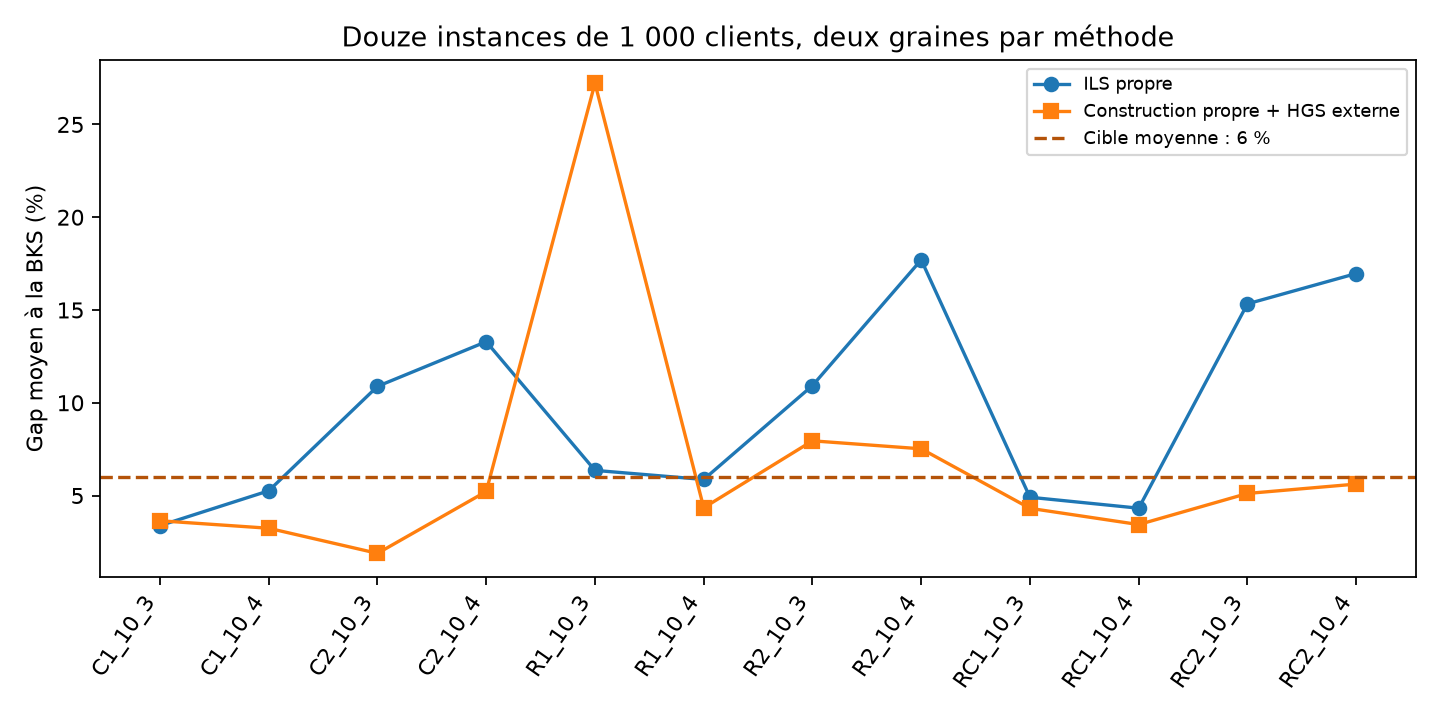

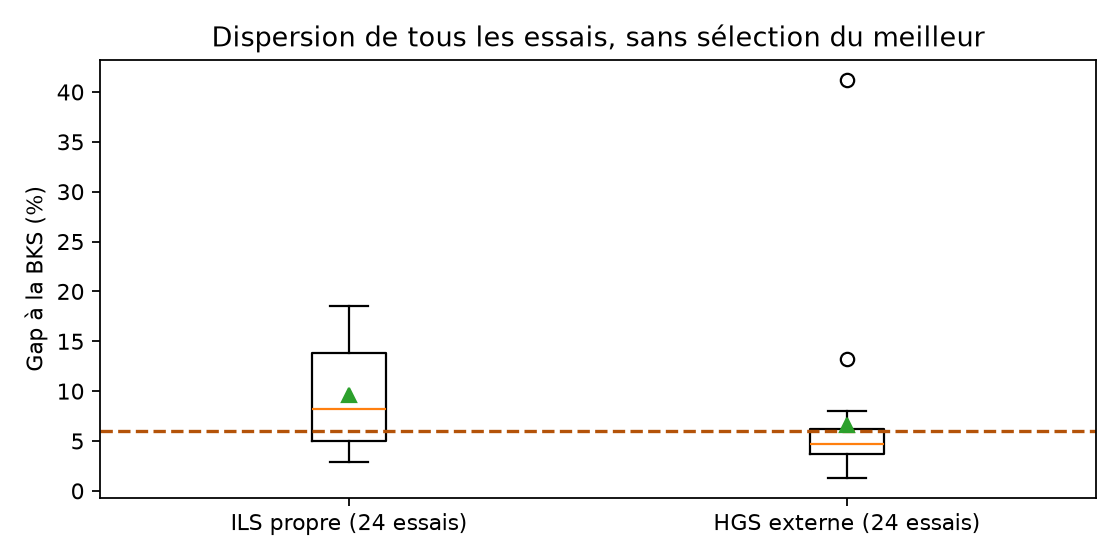

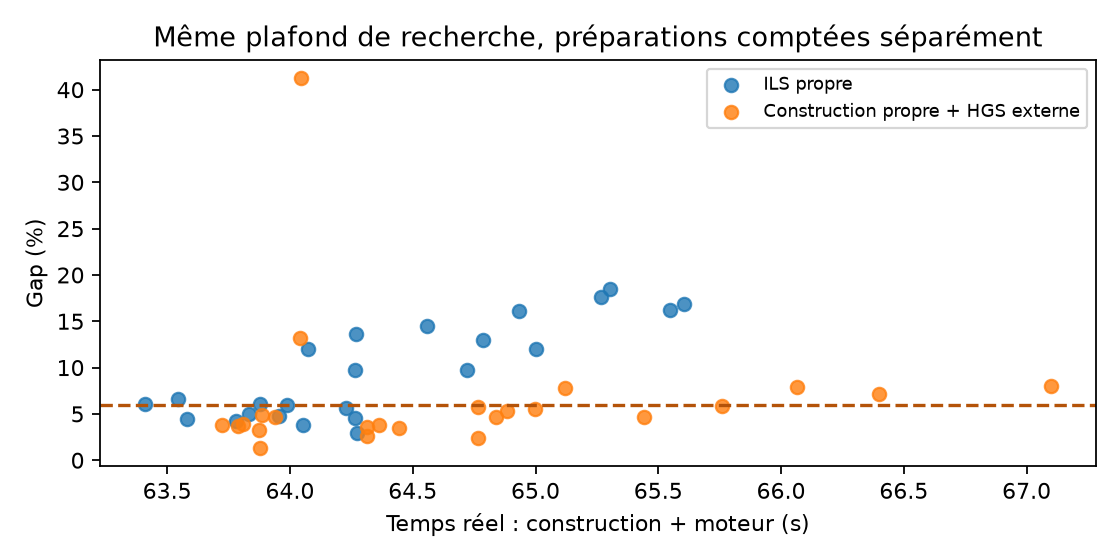

In [4]:
from IPython.display import Image, display
for name in ['comparison', 'distribution', 'time_gap']:
    display(Image(filename=str(root / 'livraison/ils_v7_figures' / (name + '.png'))))

## Résultats des pipelines : les deux phases et tout leur coût

,essais,gap_moyen,ecart_type,pire,temps_total
variant,,,,,
baseline,24,9.035800,4.975464,17.103490,124.387973
hybrid_hgs,24,4.253343,1.916544,8.109975,124.626871


,instance,seed,variant,bks,cost,vehicles,gap_pct,total_s
0,C1_10_3,2101,baseline,40060.0,41587.6,94,3.813280,124.060691
1,C1_10_3,2101,hybrid_hgs,40060.0,41202.3,93,2.851473,124.254779
2,C1_10_3,2102,baseline,40060.0,41086.4,94,2.562157,124.279456
3,C1_10_3,2102,hybrid_hgs,40060.0,40882.9,94,2.054169,124.511101
4,C1_10_4,2101,baseline,39434.1,41179.1,92,4.425104,124.271555
5,C1_10_4,2101,hybrid_hgs,39434.1,40780.1,93,3.413290,124.450911
6,C1_10_4,2102,baseline,39434.1,41439.8,92,5.086207,123.995046
7,C1_10_4,2102,hybrid_hgs,39434.1,40553.4,92,2.838406,124.284803
8,C2_10_3,2101,baseline,16036.5,17946.2,35,11.908459,124.082259
9,C2_10_3,2101,hybrid_hgs,16036.5,16259.1,30,1.388083,124.299142


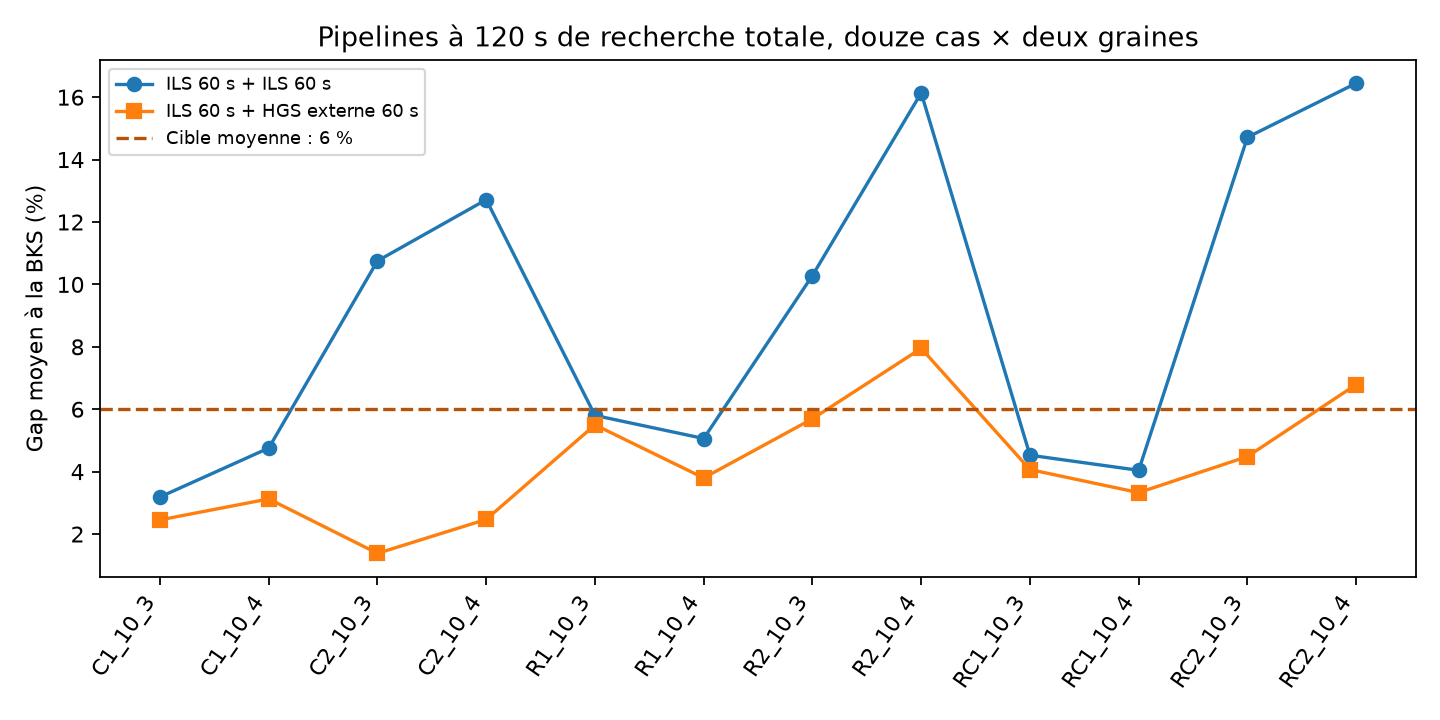

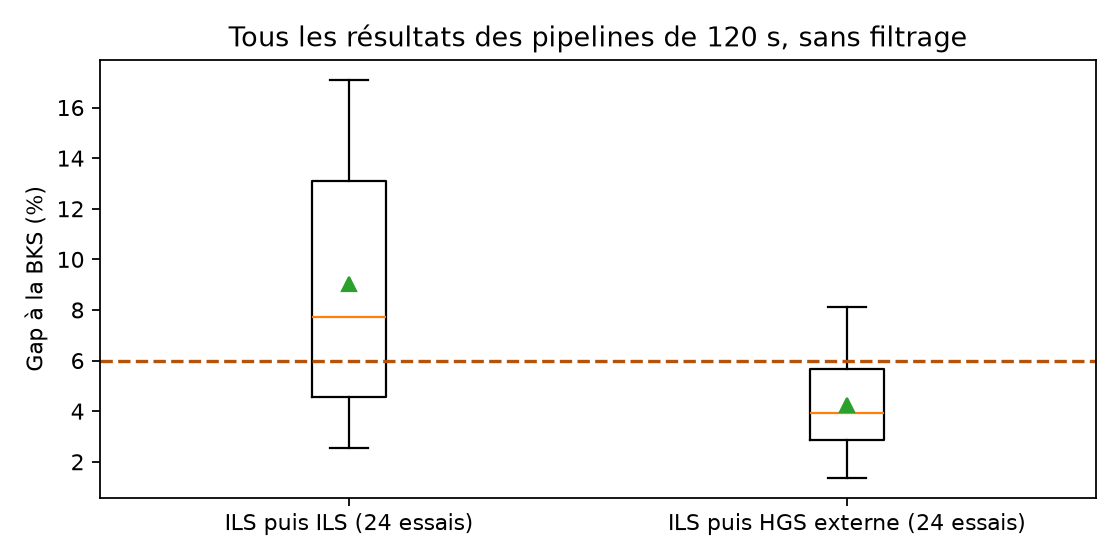

In [5]:
final = pd.read_csv(root / 'results/optimization_v7/continuation_120/flat.csv')
assert len(final) == 48 and final.valid.all()
assert np.allclose(final.total_s, final.reused_prefix_s + final.newly_executed_s)
display(final.groupby('variant').agg(essais=('gap_pct', 'size'), gap_moyen=('gap_pct', 'mean'), ecart_type=('gap_pct', 'std'), pire=('gap_pct', 'max'), temps_total=('total_s', 'mean')))
display(final[['instance', 'seed', 'variant', 'bks', 'cost', 'vehicles', 'gap_pct', 'total_s']].sort_values(['instance','seed','variant']))
for name in ['comparison_120','distribution_120']:
    display(Image(filename=str(root / 'livraison/ils_v7_figures' / (name + '.png'))))